In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("e-comm_dataset.csv", encoding="utf-8", encoding_errors="ignore")

In [259]:
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,cost,unit_cost,selling_price,months,order_months,order_year,ship_months,ship_year,order_month_no,days_to_ship
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,220.0464,110.0232,261.96,November,November,2016,November,2016,11,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,512.3580,170.7860,731.94,November,November,2016,November,2016,11,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,7.7486,3.8743,14.62,June,June,2016,June,2016,06,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,1340.6085,268.1217,1741.05,October,October,2015,October,2015,10,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,19.8516,9.9258,27.96,October,October,2015,October,2015,10,7


In [11]:
df['Customer ID'].nunique()

793

In [285]:
# Converting alphabets into lower case and removing the space between them
df.columns = df.columns.str.lower()
df.columns = df.columns.str.strip().str.replace(" ","_")

In [17]:
df.columns

Index(['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode',
       'customer_id', 'customer_name', 'segment', 'country', 'city', 'state',
       'postal_code', 'region', 'product_id', 'category', 'sub-category',
       'product_name', 'sales', 'quantity', 'discount', 'profit'],
      dtype='object')

In [19]:
df.describe()

,row_id,postal_code,sales,quantity,discount,profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [43]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

In [22]:
df['product_name'].nunique()

1850

In [23]:
df['category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [24]:
df['region'].unique()

array(['South', 'West', 'Central', 'East'], dtype=object)

In [26]:
df['city'].nunique()

531

In [28]:
df['state'].nunique()

49

In [29]:
df['country'].unique()

array(['United States'], dtype=object)

In [30]:
df['segment'].unique()

array(['Consumer', 'Corporate', 'Home Office'], dtype=object)

In [36]:
df[['sales','profit','cost']]

,sales,profit,cost
0,261.9600,41.9136,220.0464
1,731.9400,219.5820,512.3580
2,14.6200,6.8714,7.7486
3,957.5775,-383.0310,1340.6085
4,22.3680,2.5164,19.8516
...,...,...,...
9989,25.2480,4.1028,21.1452
9990,91.9600,15.6332,76.3268
9991,258.5760,19.3932,239.1828
9992,29.6000,13.3200,16.2800


In [54]:
df['order_months'] = df['order_date'].dt.strftime('%B')

In [74]:
df['order_month_no'] = df['order_date'].dt.strftime('%m')

In [55]:
df['order_year'] = df['order_date'].dt.strftime('%Y')

In [100]:
df['ship_year'] = df['ship_date'].dt.strftime('%Y')

In [57]:
df['ship_months'] = df['ship_date'].dt.strftime('%B')

In [58]:
df['ship_year'] = df['ship_date'].dt.strftime('%Y')

In [284]:
# Calculating sales in each month across different years
monthly_sales_df = df.pivot_table(
    values='sales',
    index='order_month_no',
    columns='order_year',
    aggfunc='sum'
    )
monthly_sales_df

order_year,2014,2015,2016,2017
order_month_no,,,,
01,14236.8950,18174.0756,18542.4910,43971.3740
02,4519.8920,11951.4110,22978.8150,20301.1334
03,55691.0090,38726.2520,51715.8750,58872.3528
04,28295.3450,34195.2085,38750.0390,36521.5361
05,23648.2870,30131.6865,56987.7280,44261.1102
06,34595.1276,24797.2920,40344.5340,52981.7257
07,33946.3930,28765.3250,39261.9630,45264.4160
08,27909.4685,36898.3322,31115.3743,63120.8880
09,81777.3508,64595.9180,73410.0249,87866.6520


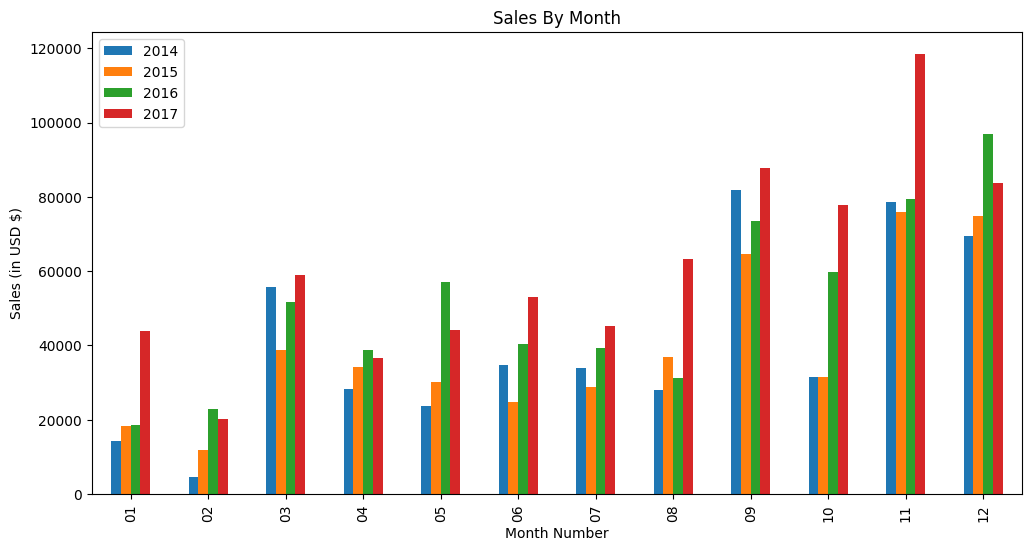

In [108]:
monthly_sales_df.plot(kind='bar',figsize=(12,6))
plt.title("Sales By Month")
plt.xlabel("Month Number")
plt.ylabel("Sales (in USD $)")
plt.legend(loc='upper left')

In [107]:
# Calculating profit in each month across different years

monthly_profit_df = df.pivot_table(
    values='profit',
    index='order_month_no',
    columns='order_year',
    aggfunc='sum'
    )
monthly_profit_df

order_year,2014,2015,2016,2017
order_month_no,,,,
01,2450.1907,-3281.0070,2824.8233,7140.4391
02,862.3084,2813.8508,5004.5795,1613.8720
03,498.7299,9732.0978,3611.9680,14751.8915
04,3488.8352,4187.4962,2977.8149,933.2900
05,2738.7096,4667.8690,8662.1464,6342.5828
06,4976.5244,3335.5572,4750.3781,8223.3357
07,-841.4826,3288.6483,4432.8779,6952.6212
08,5318.1050,5355.8084,2062.0693,9040.9557
09,8328.0994,8209.1627,9328.6576,10991.5556


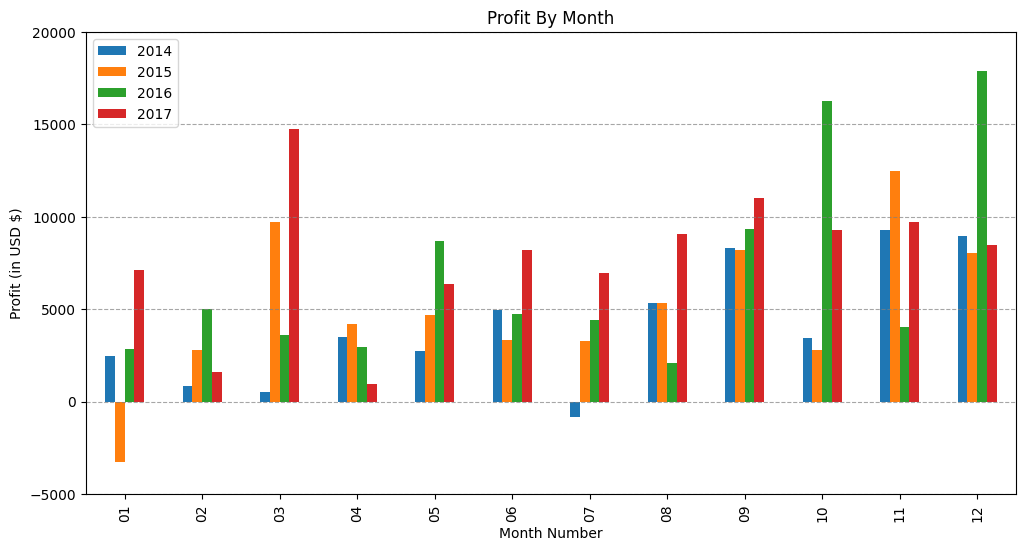

In [109]:
monthly_profit_df.plot(kind='bar',figsize=(12,6))
plt.title("Profit By Month")
plt.xlabel("Month Number")
plt.ylabel("Profit (in USD $)")
plt.legend(loc='upper left')
plt.ylim(-5000, 20000)
plt.grid(axis='y', linestyle='--', alpha=0.7, color='gray')

In [258]:
# Calculating total profit
total_profit = df['profit'].sum()
print("=" * 30)
print(f"    TOTAL PROFIT    ")
print("=" * 30)
print(f"   $ {total_profit:,.2f}   ")
print("=" * 30)

    TOTAL PROFIT    
   $ 286,397.02   


In [283]:
# Calculating total sales
total_sales = df['sales'].sum()
print("=" * 30)
print(f"    TOTAL SALES    ")
print("=" * 30)
print(f"   $ {total_sales:,.2f}   ")
print("=" * 30)

    TOTAL SALES    
   $ 2,297,200.86   


In [282]:
# Calculating overall profit margin
total_profit_margin = (total_profit / total_sales)*100
print("=" * 30)
print(f"     OVERALL PROFIT MARGIN    ")
print("=" * 30)
print(f"        {total_profit_margin:,.2f}%   ")
print("=" * 30)

     OVERALL PROFIT MARGIN    
        12.47%   


In [281]:
# Calculating which month has high profit in each year

flat_profit = monthly_profit_df.unstack().reset_index()
flat_profit.columns = ['year', 'month', 'profit']
high_profit = flat_profit.loc[flat_profit.groupby('year')['profit'].idxmax()]
high_profit

,year,month,profit
10,2014,11,9292.1269
22,2015,11,12474.7884
35,2016,12,17885.3093
38,2017,03,14751.8915


In [280]:
# Calculating which month has low profit in each year

low_profit = flat_profit.loc[flat_profit.groupby('year')['profit'].idxmin()]
low_profit

,year,month,profit
6,2014,07,-841.4826
12,2015,01,-3281.0070
31,2016,08,2062.0693
39,2017,04,933.2900


In [279]:
# Calculating which month has high sales in each year

flat_sales = monthly_sales_df.unstack().reset_index()
flat_sales.columns = ['year','month','sales']
high_sales = flat_sales.loc[flat_sales.groupby('year')['sales'].idxmax()]
high_sales

,year,month,sales
8,2014,09,81777.3508
22,2015,11,75972.5635
35,2016,12,96999.0430
46,2017,11,118447.8250


In [278]:
# Calculating which month has low sales in each year

low_sales = flat_sales.loc[flat_sales.groupby('year')['sales'].idxmin()]
low_sales

,year,month,sales
1,2014,02,4519.8920
13,2015,02,11951.4110
24,2016,01,18542.4910
37,2017,02,20301.1334


# Sales and Financial Performance
### • Cumulative Net Profit: 
The company generated a healthy total profit of $286,397 over the 4-year period.

### • Resilience to Downturns: 
The business demonstrated strong baseline stability, absorbing only two minor unprofitable months: July 2014 (841 USD) and January 2015 (3,281 USD) before quickly returning to profitability.

In [277]:
# Calculating total sales for each year of different categories

sales_analyse_by_cat = df.pivot_table(
    values = 'sales',
    index = 'order_year',
    columns = 'category',
    aggfunc = 'sum'
)
sales_analyse_by_cat

category,Furniture,Office Supplies,Technology
order_year,,,
2014,157192.8531,151776.412,175278.233
2015,170518.2370,137233.463,162780.809
2016,198901.4360,183939.982,226364.180
2017,215387.2692,246097.175,271730.811


Text(0.5, 0, 'Year')

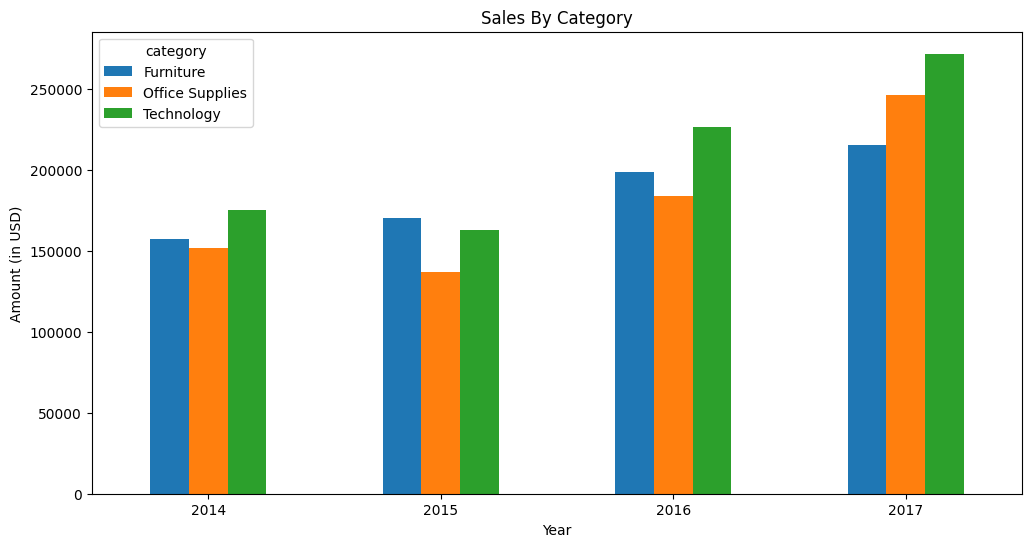

In [173]:
sales_analyse_by_cat.plot(kind='bar',figsize=(12,6))
plt.xticks(rotation=0)
plt.title("Sales By Category")
plt.ylabel("Amount (in USD)")
plt.xlabel("Year")

In [276]:
# Calculating total sales for each year of different sub-categories

sales_analyse_by_subcat = df.pivot_table(
    values = 'sales',
    index = 'sub-category',
    columns = 'order_year',
    aggfunc = 'sum'
)
sales_analyse_by_subcat

order_year,2014,2015,2016,2017
sub-category,,,,
Accessories,25014.2720,40523.9600,41895.8540,59946.2320
Appliances,15313.6250,23241.2890,26050.3150,42926.9320
Art,6057.9820,6236.8340,5960.9080,8863.0680
Binders,43488.2650,37453.0980,49683.3250,72788.0450
Bookcases,20036.6776,38543.5725,26275.4665,30024.2797
Chairs,77241.5760,71734.5290,83918.6450,95554.3530
Copiers,10849.7820,26179.4500,49599.4100,62899.3880
Envelopes,3855.7500,4512.1880,4729.8900,3378.5740
Fasteners,661.3280,545.2240,960.1340,857.5940


Text(0.5, 0, 'Sub-Category')

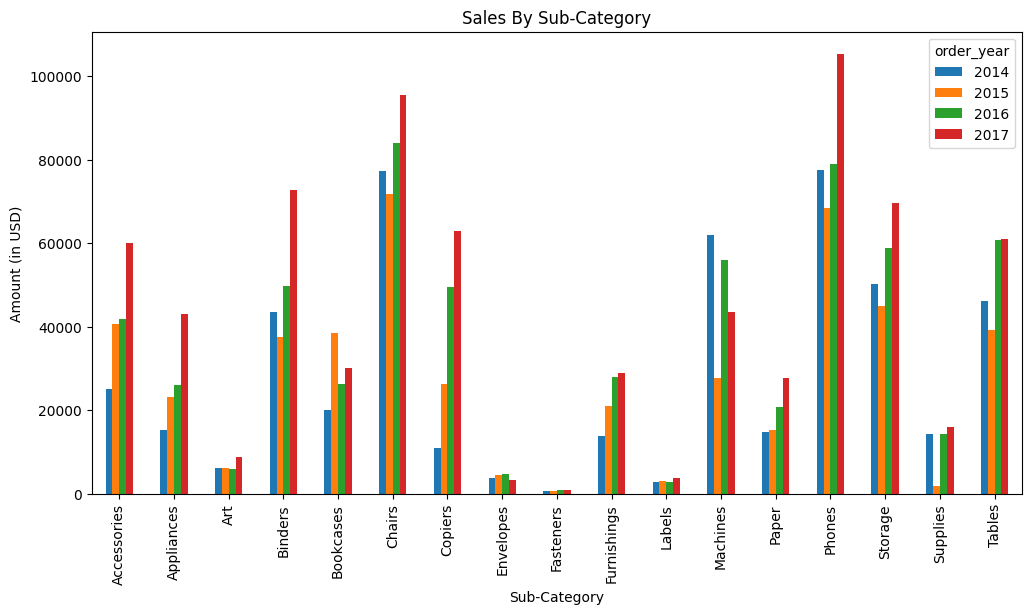

In [175]:
sales_analyse_by_subcat.plot(kind='bar',figsize=(12,6))
plt.title("Sales By Sub-Category")
plt.ylabel("Amount (in USD)")
plt.xlabel("Sub-Category")

In [275]:
# Calculating total profit for each year of different categories

profit_analyse_by_cat = df.pivot_table(
    values = 'profit',
    index = 'order_year',
    columns = 'category',
    aggfunc = 'sum'
)
profit_analyse_by_cat

category,Furniture,Office Supplies,Technology
order_year,,,
2014,5457.7255,22593.4161,21492.8325
2015,3015.2029,25099.5338,33503.8670
2016,6959.9531,35061.2292,39773.9920
2017,3018.3913,39736.6217,50684.2566


Text(0.5, 0, 'Year')

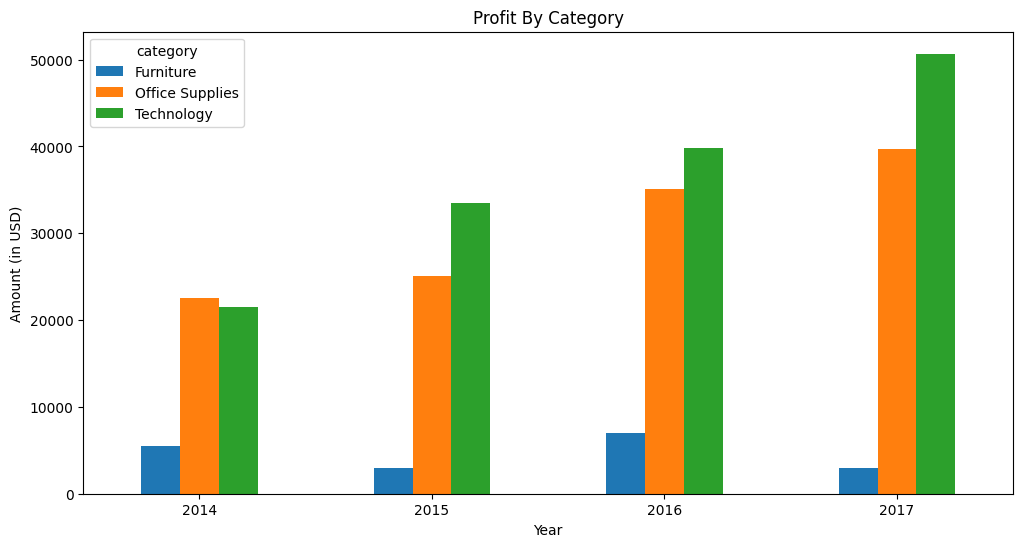

In [182]:
profit_analyse_by_cat.plot(kind='bar',figsize=(12,6))
plt.xticks(rotation=0)
plt.title("Profit By Category")
plt.ylabel("Amount (in USD)")
plt.xlabel("Year")
# plt.grid(axis='y', linestyle='--', alpha=0.7, color='gray')

In [274]:
# Calculating total profit for each year of different sub-categories

profit_analyse_by_subcat = df.pivot_table(
    values = 'profit',
    index = 'sub-category',
    columns = 'order_year',
    aggfunc = 'sum'
)
profit_analyse_by_subcat

order_year,2014,2015,2016,2017
sub-category,,,,
Accessories,6402.7150,10197.2752,9664.2885,15672.3570
Appliances,2459.4999,2511.8957,5301.3415,7865.2683
Art,1406.8031,1485.0582,1413.9626,2221.9631
Binders,4739.7160,7596.6714,10215.6341,7669.7418
Bookcases,-346.1707,-2755.2302,212.4710,-583.6261
Chairs,6955.0470,6228.4161,5763.1539,7643.5493
Copiers,2912.9433,9930.2988,17742.7926,25031.7902
Envelopes,1495.4788,1960.1906,2066.7483,1441.7590
Fasteners,178.5583,171.9376,294.0734,304.9489


Text(0.5, 0, 'Sub-Category')

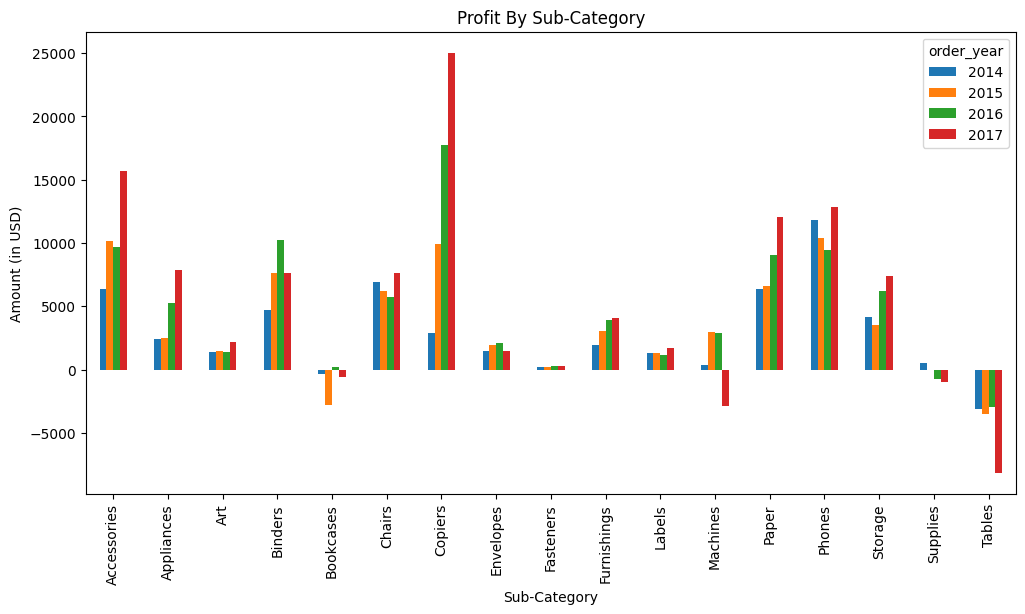

In [184]:
profit_analyse_by_subcat.plot(kind='bar',figsize=(12,6))
plt.title("Profit By Sub-Category")
plt.ylabel("Amount (in USD)")
plt.xlabel("Sub-Category")

In [272]:
# products with high profit
products_by_profit_year = df.groupby(['product_name','order_year'])['profit'].sum().sort_values(ascending=False)

In [273]:
# Top 5 high profitable product of each year
top_5_by_year = products_by_profit_year.groupby(level='order_year').head(5)
top_5_by_year

product_name                                                                 order_year
Canon imageCLASS 2200 Advanced Copier                                        2017          15679.9552
                                                                             2016           9519.9728
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind  2015           7498.8410
Ibico EPK-21 Electric Binding System                                         2014           4630.4755
Hewlett Packard LaserJet 3310 Copier                                         2017           3623.9396
Zebra ZM400 Thermal Label Printer                                            2015           3343.5360
GBC Ibimaster 500 Manual ProClick Binding System                             2016           2967.8220
HP Designjet T520 Inkjet Large Format Printer - 24" Color                    2016           2799.9840
Hewlett Packard LaserJet 3310 Copier                                         2016           2783

In [271]:
# Top 5 high profitable product 

products_by_profit = df.groupby('product_name')['profit'].sum().sort_values(ascending=False).head(5)
products_by_profit

product_name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Name: profit, dtype: float64

In [270]:
# Top 5 least profitable and high sales product

products_and_sales = df.groupby('product_name')[['profit','sales']].sum().sort_values( by=['profit','sales'], ascending=[True,False]).head(5)

In [203]:
products_and_sales

,profit,sales
product_name,,
Cubify CubeX 3D Printer Double Head Print,-8879.9704,11099.963
Lexmark MX611dhe Monochrome Laser Printer,-4589.9730,16829.901
Cubify CubeX 3D Printer Triple Head Print,-3839.9904,7999.980
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.1156,9917.640
Bush Advantage Collection Racetrack Conference Table,-1934.3976,9544.725


# Product Performance Analysis

### • 🚀 Technology is the Primary Engine: 
Technology is your standout performer. Its annual profit grew consistently by approximately $10,000 each year, climbing from $21,493 in 2014 to a dominant $50,684 by 2017, driven by robust sales acceleration.

### • 📈 Office Supplies Shows Superior Efficiency:
Despite a temporary sales dip in 2015 ($137,233), the Office Supplies category maintained an uncompromised upward profit trajectory every single year. By 2017, it reached peak sales of $246,097 with a highly efficient profit yield of $39,737.

### • ⚠️ The Furniture Profitability Trap: 
While Furniture generates massive top-line sales volume (surpassing $215k by 2017), its profitability is highly volatile and alarmingly weak. In both 2015 and 2017, profits plummeted back down to the $3,000 mark, indicating severe margin erosion despite scaling sales.


In [269]:
# Sales and profit based on different regions
sales_profit_region = df.groupby('region')[['sales','profit']].sum().sort_values( by=['profit','sales'], ascending=[False,False])
sales_profit_region

,sales,profit
region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
South,391721.9050,46749.4303
Central,501239.8908,39706.3625


In [268]:
# Sales and profit based on different segment

sales_profit_segment = df.groupby('segment')[['sales','profit']].sum()
sales_profit_segment['profit_margin_%'] = (sales_profit_segment['profit'] / sales_profit_segment['sales']) * 100

# Sort by the most profitable margin percentage
sales_profit_segment = sales_profit_segment.sort_values(by=['sales','profit_margin_%'], ascending=[False,True])
sales_profit_segment.style.format({'sales': '${:,.2f}', 'profit': '${:,.2f}', 'profit_margin_%': '{:,.2f}%'})

,sales,profit,profit_margin_%
segment,,,
Consumer,"$1,161,401.34","$134,119.21",11.55%
Corporate,"$706,146.37","$91,979.13",13.03%
Home Office,"$429,653.15","$60,298.68",14.03%


In [260]:
sales_profit_region = df.groupby('region')[['sales','profit']].sum()
sales_profit_region['profit_margin_%'] = (sales_profit_region['profit'] / sales_profit_region['sales']) * 100

# Sort by the most profitable margin percentage
sales_profit_region = sales_profit_region.sort_values(by=['sales','profit_margin_%'], ascending=[False,False])
sales_profit_region.style.format({'sales': '${:,.2f}', 'profit': '${:,.2f}', 'profit_margin_%': '{:,.2f}%'})

,sales,profit,profit_margin_%
region,,,
West,"$725,457.82","$108,418.45",14.94%
East,"$678,781.24","$91,522.78",13.48%
Central,"$501,239.89","$39,706.36",7.92%
South,"$391,721.91","$46,749.43",11.93%



# Region & Customer Segment Analysis


### Core Performance

• The Consumer Segment is Our Growth Engine: It drives the highest absolute volume, bringing in $1,161,401.34 in sales and generating $134,119.21 in net profit.
• Home Office Delivers Top Efficiency: While it brings in the lowest absolute revenue ($429k), it yields our highest operational efficiency with a 14.03% profit margin.

### Geographic Standouts

• The West Region Leads the Nation: The West is our star territory, generating both the highest sales ($725,457.82) and the most efficient profit margin at 14.94%.
• The Central Region is a Major Red Flag: Despite pulling in a solid $501,239.89 in sales, the Central region drags down company performance with a weak 7.92% profit margin—nearly half the efficiency of the West.


In [211]:
df['discount'].describe()

count    9994.000000
mean        0.156203
std         0.206452
min         0.000000
25%         0.000000
50%         0.200000
75%         0.200000
max         0.800000
Name: discount, dtype: float64

In [219]:
df['discount'].median()

np.float64(0.2)

In [216]:
df['discount'].value_counts(normalize=True)*100

discount
0.00    48.008805
0.20    36.591955
0.70     4.182510
0.80     3.001801
0.30     2.271363
0.40     2.061237
0.60     1.380828
0.10     0.940564
0.50     0.660396
0.15     0.520312
0.32     0.270162
0.45     0.110066
Name: proportion, dtype: float64

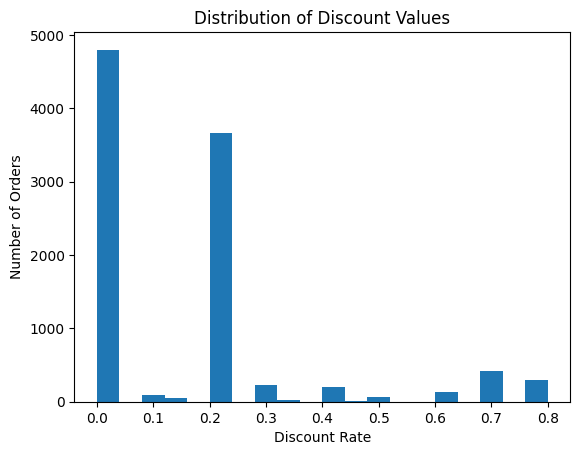

In [218]:
df['discount'].plot(kind='hist', bins=20, title='Distribution of Discount Values')
plt.xlabel('Discount Rate')
plt.ylabel('Number of Orders')
plt.show()


In [221]:
# 1. Create filters for full price vs 20% discount
full_price_orders = df[df['discount'] == 0.0]
standard_discount_orders = df[df['discount'] == 0.2]

# 2. Compare the average profit made in both scenarios
print("Average Profit at Full Price (0%):", full_price_orders['profit'].mean())
print("Average Profit at Standard Discount (20%):", standard_discount_orders['profit'].mean())


Average Profit at Full Price (0%): 66.90029245518967
Average Profit at Standard Discount (20%): 24.702572053595848


In [222]:
# Group by discount rate to see total profit vs total sales for each tier
discount_impact = df.groupby('discount')[['sales', 'profit']].agg(['sum', 'count', 'mean'])
print(discount_impact)


                 sales                         profit                  
                   sum count        mean          sum count        mean
discount                                                               
0.00      1.087908e+06  4798  226.742074  320987.6032  4798   66.900292
0.10      5.436935e+04    94  578.397351    9029.1770    94   96.055074
0.15      2.755852e+04    52  529.971567    1418.9915    52   27.288298
0.20      7.645944e+05  3657  209.076940   90337.3060  3657   24.702572
0.30      1.032267e+05   227  454.742974  -10369.2774   227  -45.679636
0.32      1.449346e+04    27  536.794770   -2391.1377    27  -88.560656
0.40      1.164178e+05   206  565.134874  -23057.0504   206 -111.927429
0.45      5.484974e+03    11  498.634000   -2493.1111    11 -226.646464
0.50      5.891854e+04    66  892.705152  -20506.4281    66 -310.703456
0.60      6.644700e+03   138   48.150000   -5944.6552   138  -43.077212
0.70      4.062028e+04   418   97.177708  -40075.3569   418  -95

In [267]:
# Categories with negative profit with high discount
grouped_cat_profit = df.groupby(['category','discount'])[['sales','profit']].sum()
negative_profit_area = grouped_cat_profit[grouped_cat_profit['profit'] < 0 ].sort_values(by='profit', ascending=True)
negative_profit_area.style.format({'sales': '${:,.2f}', 'profit': '${:,.2f}'})

In [266]:
# Sub-categories with negative profit with high discount
grouped_subcat_profit = df.groupby(['sub-category','discount'])[['sales','profit']].sum()
negative_profit_area = grouped_subcat_profit[grouped_subcat_profit['profit'] < 0 ].sort_values(by='profit', ascending=True)
negative_profit_area.style.format({'sales': '${:,.2f}', 'profit': '${:,.2f}'})

,,sales,profit
sub-category,discount,,
Binders,0.800000,"$13,581.22","$-21,909.40"
Machines,0.700000,"$15,601.51","$-19,579.32"
Binders,0.700000,"$22,559.39","$-16,601.10"
Tables,0.400000,"$45,614.41","$-16,187.40"
Appliances,0.800000,"$3,382.53","$-8,629.64"
Tables,0.500000,"$13,675.01","$-8,615.39"
Machines,0.500000,"$37,935.07","$-7,635.23"
Chairs,0.300000,"$70,005.50","$-6,737.12"
Phones,0.400000,"$34,337.35","$-6,385.79"



# Discount Impact & Category Leaks Analysis


### The Discount Thresholds

The 20% discount group was profitable, but the no-discount group generated substantially more total profit.
Transaction groups with discounts of 30% or more recorded negative aggregate profit. Management should investigate the products and sub-categories within these groups before changing discount policy.

### Critical Profit Leaks by Category

• Office Supplies (80% Discount): Our single biggest profit drain. Giving an 80% markdown resulted in $16.9k in sales but caused a crushing $30,539.04 net loss.
• Technology (70% Discount): Deep markdowns on high-value Tech items wiped out $19,579.32 in profit on just $15.6k of sales.
• Furniture (30% to 40% Discounts): Furniture margins are dangerously thin. Even a moderate 30% discount loses $10,695.32, explaining why overall Furniture profits fluctuate so wildly year-to-year.

In [265]:
# Create column days to ship product
df['days_to_ship'] = (df['ship_date'] - df['order_date']).dt.days

In [264]:
# Calculating average dispatch interval by Ship Mode
avg_dispatch_by_mode = df.groupby('ship_mode')['days_to_ship'].mean().round(0)
avg_dispatch_by_mode

ship_mode
First Class       2.0
Same Day          0.0
Second Class      3.0
Standard Class    5.0
Name: days_to_ship, dtype: float64

In [263]:
# Calculating average dispatch intervals across regions
avg_dispatch_by_region = df.groupby('region')['days_to_ship'].mean().round(0)
avg_dispatch_by_region

region
Central    4.0
East       4.0
South      4.0
West       4.0
Name: days_to_ship, dtype: float64

In [262]:
orders = df[
    ['order_id', 'order_date', 'ship_date',
     'ship_mode', 'region']
].drop_duplicates(subset='order_id').copy()

orders['days_to_ship'] = (
    orders['ship_date'] - orders['order_date']
).dt.days

orders.groupby('ship_mode')['days_to_ship'].mean().round(0)

ship_mode
First Class       2.0
Same Day          0.0
Second Class      3.0
Standard Class    5.0
Name: days_to_ship, dtype: float64

In [286]:
from sqlalchemy import create_engine

#connect to postgres 
username = 'postgres'
host='localhost'
password='Adnan123'
port = '5432'
database = 'e-comm_sales'

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# load Dataframe into postgres
table = 'sales'
df.to_sql(table,engine,if_exists='replace',index=False)
print("Data loaded Successfully")

Data loaded Successfully
